In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt
import joblib

df = pd.read_csv("student-mat.csv", sep=";")

features = ["studytime","G2","absences","freetime","Dalc"]
target = "G3"

X = df[features]
y = df[target]

# split data set
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=40
)

In [2]:
# Model training

model = LinearRegression()

model.fit(X_train,y_train)
print(model.coef_)
joblib.dump(model,"student_model.pkl")

print("Model training is complete")

[-0.10009899  1.10977036  0.034473    0.11389429 -0.05979782]
Model training is complete


In [3]:
# prediction part
predictions = model.predict(X_train)
print(predictions[:5])

# score
print(model.score(X_test,y_test))

[12.95722759  6.38490913  5.20036459  6.10329693 11.58652274]
0.839452283233352


In [4]:
predictions = model.predict(X_test)
print("predictions: ", predictions[:5])
print("Actual: ", y_test.values[:5])

# print(X_test.iloc[1])


predictions:  [10.39733109 -1.76519456 10.2282861   9.03324827  6.67886271]
Actual:  [11  0 11  9  8]


1.0810051878684461
3.1051744584952012


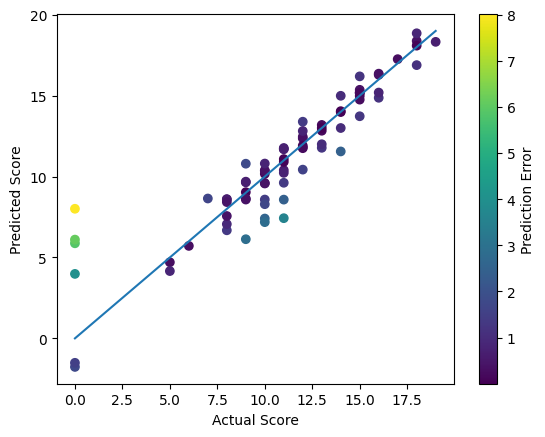

In [5]:
# MAE Test
mae = mean_absolute_error(y_test, predictions)
print(mae)

# MSE Test
mse = mean_squared_error(y_test,predictions)
print(mse)

#The Visual Test
errors = abs(y_test - predictions)
plt.scatter(y_test,predictions, c=errors)
plt.plot([y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()])
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.colorbar(label = "Prediction Error")

plt.show()

In [7]:
# Show which features improve and affect the student
print("features Impact: ")
for features, coef in zip(features, model.coef_):
    print(f"{features}:{coef}")

features Impact: 
studytime:-0.10009898999600586
G2:1.1097703580873888
absences:0.03447300328916447
freetime:0.11389428820715522
Dalc:-0.05979781575902576
